Для решения задачи классификации методами опорных векторов (SVM) и решающих деревьев (Decision Tree) используем датасет из промежуточной аттестации, описывающий работу промышленного оборудования. 

Деревья решений позволят уловить нелинейные пороговые зависимости износа станков, а метод опорных векторов построит оптимальную разделяющую гиперплоскость в пространстве признаков.
Целевая переменная Y:
failure_next_24h (бинарный признак: 1 — до аварийного останова оборудования осталось менее 24 часов, 0 — штатная работа).
Объясняющие переменные (X):
1. start_count количество запусков за интервал.
2. rpm_std стандартное отклонение скорости вращения.
3. vib_std стандартное отклонение вибрации.
4. temp_std стандартное отклонение температуры.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from imblearn.under_sampling import RandomUnderSampler

In [4]:
# 1. Загрузка и хронологическая сортировка данных
df = pd.read_csv("../v_machine_features_predictive.csv", parse_dates=['snapshot_time'])
df = df.sort_values('snapshot_time').reset_index(drop=True)

target = 'failure_next_24h'
features = ['start_count', 'rpm_std', 'vib_std', 'temp_std']

df_data = df[['machine_id', target] + features].copy()

In [5]:
df_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 395520 entries, 0 to 395519
Data columns (total 6 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   machine_id        395520 non-null  int64  
 1   failure_next_24h  395520 non-null  int64  
 2   start_count       395520 non-null  int64  
 3   rpm_std           9371 non-null    float64
 4   vib_std           20294 non-null   float64
 5   temp_std          31955 non-null   float64
dtypes: float64(3), int64(3)
memory usage: 18.1 MB


In [6]:

# 2. Импутация пропусков по времени внутри каждого станка
df_data[features] = df_data.groupby('machine_id')[features].ffill()
df_data[features] = df_data.groupby('machine_id')[features].bfill()
for col in features:
    df_data[col] = df_data[col].fillna(df_data[col].median())

df_data = df_data[[target] + features]
df_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 395520 entries, 0 to 395519
Data columns (total 5 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   failure_next_24h  395520 non-null  int64  
 1   start_count       395520 non-null  int64  
 2   rpm_std           395520 non-null  float64
 3   vib_std           395520 non-null  float64
 4   temp_std          395520 non-null  float64
dtypes: float64(3), int64(2)
memory usage: 15.1 MB


In [ ]:
# 3. Хронологическое разделение 80/20
X = df_data[features]
y = df_data[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)


# 4. Балансировка Train (берем все отказы и часть нормальных строки -> пропорция 1:2)
rus = RandomUnderSampler(sampling_strategy=0.5, random_state=42)
X_train_res, y_train_res = rus.fit_resample(X_train, y_train)

print("Размер сбалансированного Train:", y_train_res.value_counts().to_dict())
print("Размер честного Test:", y_test.value_counts().to_dict())

# 5. Масштабирование
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_res)
X_test_scaled = scaler.transform(X_test)

Размер сбалансированного Train: {0: 5764, 1: 2882}
Размер честного Test: {0: 78462, 1: 642}


/var/data/python/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/var/data/python/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/var/data/python/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/var/data/python/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in versio

Лучшие гиперпараметры SVM: {'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}

--- ОТЧЕТ ПО МЕТРИКАМ: SVM (Тестовая выборка) ---
              precision    recall  f1-score   support

   Норма (0)       0.99      0.94      0.96     78462
   Отказ (1)       0.01      0.08      0.02       642

    accuracy                           0.93     79104
   macro avg       0.50      0.51      0.49     79104
weighted avg       0.98      0.93      0.96     79104

ROC-AUC (SVM): 0.5430


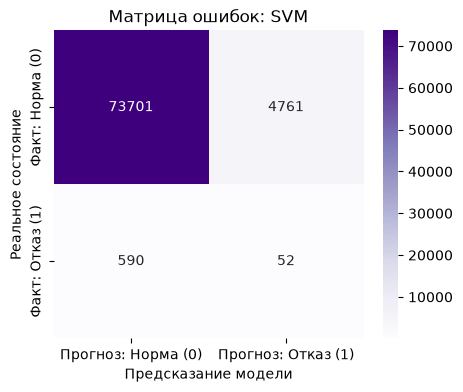

In [8]:
#  МЕТОД ОПОРНЫХ ВЕКТОРОВ (SVM) И GRIDSEARCHCV 

# Сетка гиперпараметров для перебора
param_grid_svm = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 0.1]
}

# Подбираем лучшие параметры, оптимизируя метрику F1
grid_svm = GridSearchCV(
    SVC(probability=True, random_state=42),
    param_grid_svm,
    cv=3,
    scoring='f1',
    n_jobs=-1
)
grid_svm.fit(X_train_scaled, y_train_res)

best_svm = grid_svm.best_estimator_
print("Лучшие гиперпараметры SVM:", grid_svm.best_params_)

# Делаем предсказания на тестовой выборке
y_pred_svm = best_svm.predict(X_test_scaled)
y_prob_svm = best_svm.predict_proba(X_test_scaled)[:, 1]

print("\n--- ОТЧЕТ ПО МЕТРИКАМ: SVM (Тестовая выборка) ---")
print(classification_report(y_test, y_pred_svm, target_names=['Норма (0)', 'Отказ (1)'], zero_division=0))
print(f"ROC-AUC (SVM): {roc_auc_score(y_test, y_prob_svm):.4f}")

# Строим матрицу ошибок
cm_svm = confusion_matrix(y_test, y_pred_svm)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Purples',
            xticklabels=['Прогноз: Норма (0)', 'Прогноз: Отказ (1)'],
            yticklabels=['Факт: Норма (0)', 'Факт: Отказ (1)'])
plt.title('Матрица ошибок: SVM')
plt.ylabel('Реальное состояние')
plt.xlabel('Предсказание модели')
plt.show()


• Лучшие гиперпараметры: {'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}. Поиск по сетке выбрал нелинейное радиально-базисное ядро (rbf) с высоким штрафом за ошибку (C=10), что подтверждает нелинейный характер границ износа.
• Качество на тесте: ROC-AUC = 0.5430. Из 642 реальных поломок модель поймала 52 (Recall = 8%), сгенерировав 4 761 ложное срабатывание (Precision = 1%).

Лучшие гиперпараметры Decision Tree: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_split': 14}

--- ОТЧЕТ ПО МЕТРИКАМ: Decision Tree (Тестовая выборка) ---
              precision    recall  f1-score   support

   Норма (0)       0.99      0.91      0.95     78462
   Отказ (1)       0.01      0.12      0.02       642

    accuracy                           0.90     79104
   macro avg       0.50      0.52      0.49     79104
weighted avg       0.98      0.90      0.94     79104

ROC-AUC (Decision Tree): 0.5073


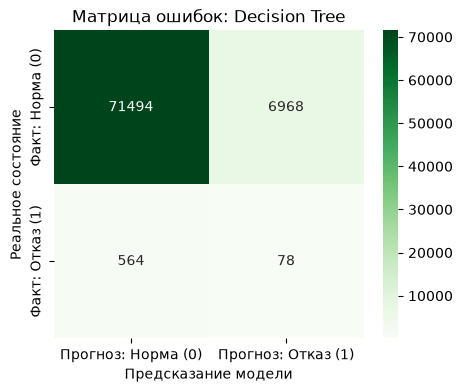

In [ ]:
# ДЕРЕВО РЕШЕНИЙ И GRIDSEARCHCV


# Сетка гиперпараметров для перебора
param_grid_dt = {
    'max_depth': list(range(3, 12, 2)),
    'min_samples_split': list(range(2, 22, 6)),
    'criterion': ['gini', 'entropy']
}

grid_dt = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid_dt,
    cv=3,
    scoring='f1',
    n_jobs=-1
)
grid_dt.fit(X_train_scaled, y_train_res)

best_dt = grid_dt.best_estimator_
print("Лучшие гиперпараметры Decision Tree:", grid_dt.best_params_)

# Предсказание на тестовой выборке
y_pred_dt = best_dt.predict(X_test_scaled)
y_prob_dt = best_dt.predict_proba(X_test_scaled)[:, 1]

print("\n--- ОТЧЕТ ПО МЕТРИКАМ: Decision Tree (Тестовая выборка) ---")
print(classification_report(y_test, y_pred_dt, target_names=['Норма (0)', 'Отказ (1)'], zero_division=0))
print(f"ROC-AUC (Decision Tree): {roc_auc_score(y_test, y_prob_dt):.4f}")

# Матрица ошибок Decision Tree
cm_dt = confusion_matrix(y_test, y_pred_dt)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Прогноз: Норма (0)', 'Прогноз: Отказ (1)'],
            yticklabels=['Факт: Норма (0)', 'Факт: Отказ (1)'])
plt.title('Матрица ошибок: Decision Tree')
plt.ylabel('Реальное состояние')
plt.xlabel('Предсказание модели')
plt.show()


Для дерева решений подобраны оптимальные параметры {'criterion': 'entropy', 'max_depth': 5, 'min_samples_split': 14}. Дерево нашло 78 реальных поломок из 642 (Recall = 12%), что в 1.5 раза выше, чем у SVM (52 поломки, Recall = 8%). Однако общая разделяющая способность дерева ниже (ROC-AUC = 0.5073 против 0.5430 у SVM).

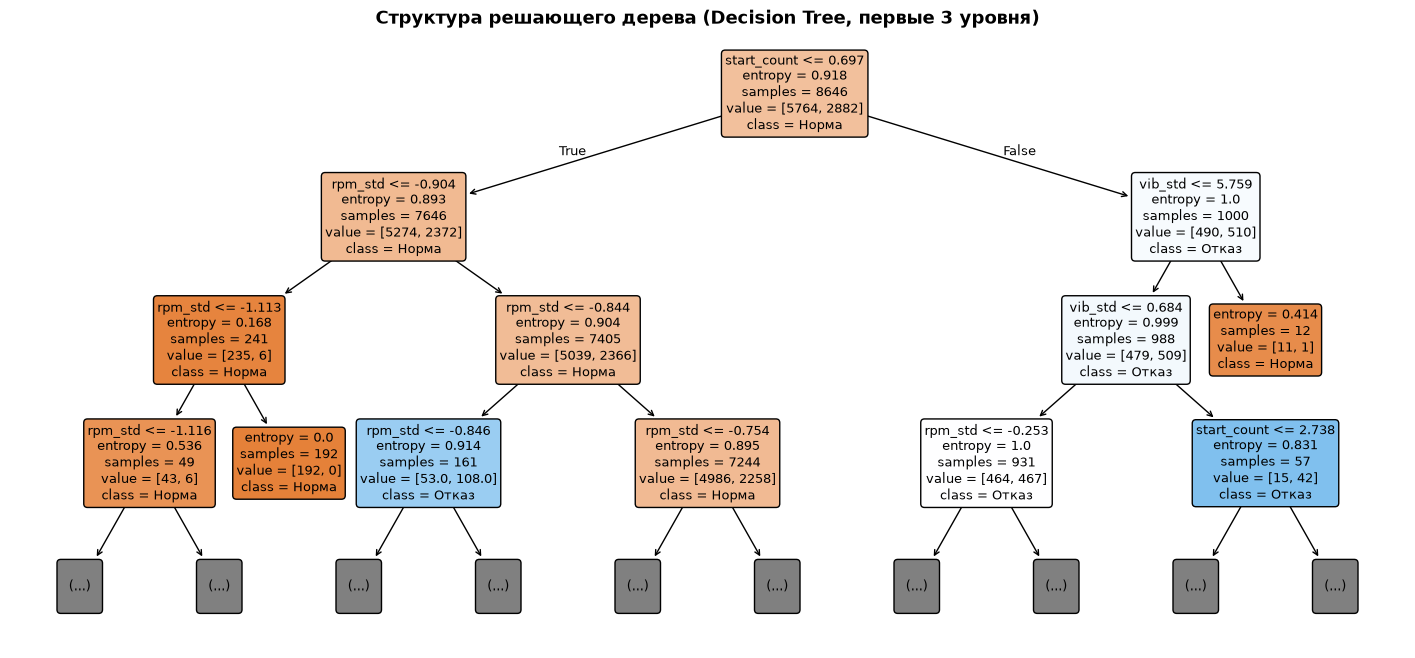

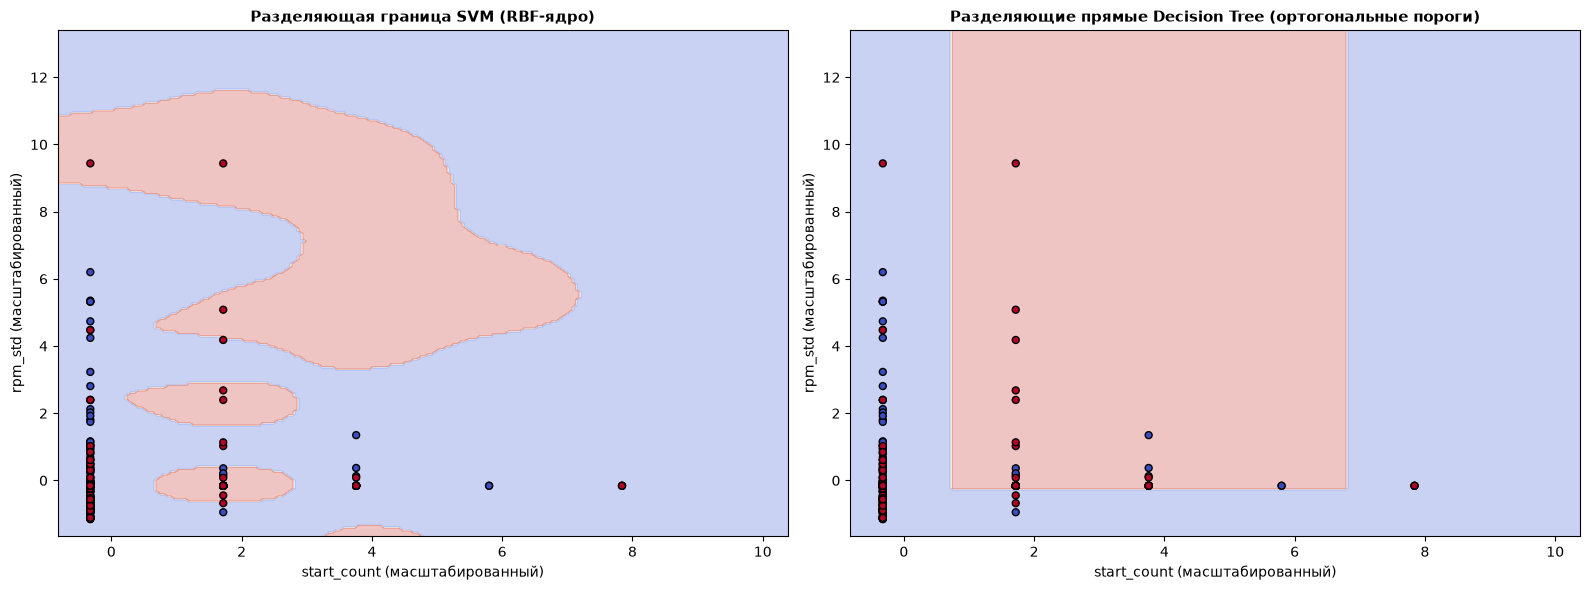

In [15]:
# ВИЗУАЛИЗАЦИЯ ДЕРЕВА И РАЗДЕЛЯЮЩИХ ГРАНИЦ

# Визуализация структуры решающего дерева (первые 3 уровня для читаемости)
plt.figure(figsize=(18, 8))
plot_tree(best_dt, max_depth=3, feature_names=features, class_names=['Норма', 'Отказ'], filled=True, rounded=True, fontsize=9)
plt.title('Структура решающего дерева (Decision Tree, первые 3 уровня)', fontsize=13, fontweight='bold')
plt.show()

# Подготовка пространства двух главных факторов: start_count (индекс 0) и rpm_std (индекс 1)
X_2d = X_train_scaled[:, slice(0, 2)]
y_2d = y_train_res.values

svm_2d = SVC(C=grid_svm.best_params_['C'], kernel=grid_svm.best_params_['kernel'], random_state=42).fit(X_2d, y_2d)
dt_2d = DecisionTreeClassifier(max_depth=4, random_state=42).fit(X_2d, y_2d)

# Координатная сетка для отрисовки областей
x_min, x_max = X_2d[:, 0].min() - 0.5, X_2d[:, 0].max() + 0.5
y_min, y_max = X_2d[:, 1].min() - 0.5, X_2d[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))

fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# График А: Нелинейная разделяющая граница SVM (RBF-ядро)
Z_svm = svm_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
ax[0].contourf(xx, yy, Z_svm, alpha=0.3, cmap='coolwarm')
ax[0].scatter(X_2d[::15, 0], X_2d[::15, 1], c=y_2d[::15], cmap='coolwarm', edgecolors='k', s=25)
ax[0].set_title('Разделяющая граница SVM (RBF-ядро)', fontsize=11, fontweight='bold')
ax[0].set_xlabel('start_count (масштабированный)')
ax[0].set_ylabel('rpm_std (масштабированный)')

# График Б: Ортогональные разделяющие прямые Decision Tree
Z_dt = dt_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
ax[1].contourf(xx, yy, Z_dt, alpha=0.3, cmap='coolwarm')
ax[1].scatter(X_2d[::15, 0], X_2d[::15, 1], c=y_2d[::15], cmap='coolwarm', edgecolors='k', s=25)
ax[1].set_title('Разделяющие прямые Decision Tree (ортогональные пороги)', fontsize=11, fontweight='bold')
ax[1].set_xlabel('start_count (масштабированный)')
ax[1].set_ylabel('rpm_std (масштабированный)')

plt.tight_layout()
plt.show()



Выводы по задаче: SVM и Decision Tree


Сравнение качества моделей на тестовой выборке

• Метод опорных векторов (SVM): Поиск по сетке (GridSearchCV) выбрал нелинейное радиально-базисное ядро rbf с параметрами C = 10 и gamma = 0.1. Модель показала более высокую общую разделяющую способность (ROC-AUC = 0.5430), однако смогла выявить лишь 52 реальных отказа из 642 (Recall = 8%) при 4 761 ложном срабатывании.
• Решающее дерево (Decision Tree): Оптимальными параметрами стали критерий энтропии (entropy), максимальная глубина max_depth = 5 и min_samples_split = 14. Дерево оказалось в 1.5 раза чувствительнее к авариям, поймав 78 реальных поломок (Recall = 12%), хотя его общая метрика ROC-AUC составила 0.5073 из-за жесткой дискретности вероятностей в листьях.
• Общий вывод по качеству: Несмотря на предварительную балансировку обучающей выборки, обе одиночные модели демонстрируют невысокую точность (Precision = 1%) на реальных несбалансированных данных (где доля отказов всего 0.89%). 

